# Name That LLM — EDA

line00 固定流程：数据概况、长度、标点与排版指纹、词汇、prompt 结构、分组 CV 基线。

数据：`assets/data/train.csv`（2,699 条 / 150 prompt / 18 模型）。所有 CV 均按 `prompt_id` 分组。

In [1]:
import re, unicodedata
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, recall_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.sparse import hstack

ROOT = Path.cwd()
while not (ROOT / 'assets/data/train.csv').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'assets/data'
pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.precision', 3)
sns.set_theme(style='whitegrid', font_scale=0.85)

FAMILY = {'gpt-5.5':'OpenAI','gpt-5.6-luna':'OpenAI','gpt-5.6-sol':'OpenAI','gpt-5.6-terra':'OpenAI','gpt-6-astra':'OpenAI',
          'gemini-3.1-pro-preview':'Google','gemini-3.6-flash':'Google','gemini-3.7-flash':'Google','gemini-3.8-flash':'Google',
          'claude-fable-5':'Anthropic','claude-opus-4-6':'Anthropic','claude-opus-4-8':'Anthropic','claude-opus-5':'Anthropic','claude-sonnet-5':'Anthropic',
          'qwen3.8-max':'Qwen','glm-5.3':'ZAI','glm-5.3-flash':'ZAI','kimi-k3':'Moonshot'}
ORDER = list(FAMILY)

tr = pd.read_csv(DATA / 'train.csv')
te = pd.read_csv(DATA / 'test.csv')
tr['family'] = tr.model.map(FAMILY)
print(tr.shape, te.shape)
tr.head()

(2699, 5) (3, 2)


,id,prompt_id,text,model,family
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max,Qwen
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5,Anthropic
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash,Google
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra,OpenAI
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash,ZAI


In [ ]:
tr[tr['prompt_id'] == 'p081']['text','']

## 1. 标签与 prompt 结构

In [2]:
print(tr.model.value_counts().describe())
per_prompt = tr.groupby('prompt_id').model.nunique()
print('prompts:', tr.prompt_id.nunique(), '| answers per prompt:', per_prompt.value_counts().to_dict())
print('缺失的 (prompt, model):', set(ORDER) - set(tr[tr.prompt_id == per_prompt.idxmin()].model))
print('重复文本:', tr.text.duplicated().sum(), '| 空文本:', tr.text.str.strip().eq('').sum())
te

count     18.000
mean     149.944
std        0.236
min      149.000
25%      150.000
50%      150.000
75%      150.000
max      150.000
Name: count, dtype: float64
prompts: 150 | answers per prompt: {18: 149, 17: 1}
缺失的 (prompt, model): {'claude-fable-5'}
重复文本: 0 | 空文本: 0


,id,text
0,00353fb1c541,"The more efficiently we use a resource, the mo..."
1,005f5a9a6139,"The Stern-Gerlach experiment, performed in 192..."
2,0062a53d5487,"Hundreds of millions of years ago, fluctuating..."


## 2. 长度

         count     mean      std    min    25%    50%     75%     max
n_char  2699.0  755.289  377.371  230.0  429.0  670.0  1027.0  1900.0
n_word  2699.0  114.660   58.281   36.0   64.0  101.0   157.0   274.0
n_para  2699.0    1.000    0.000    1.0    1.0    1.0     1.0     1.0
n_line  2699.0    1.000    0.000    1.0    1.0    1.0     1.0     1.0


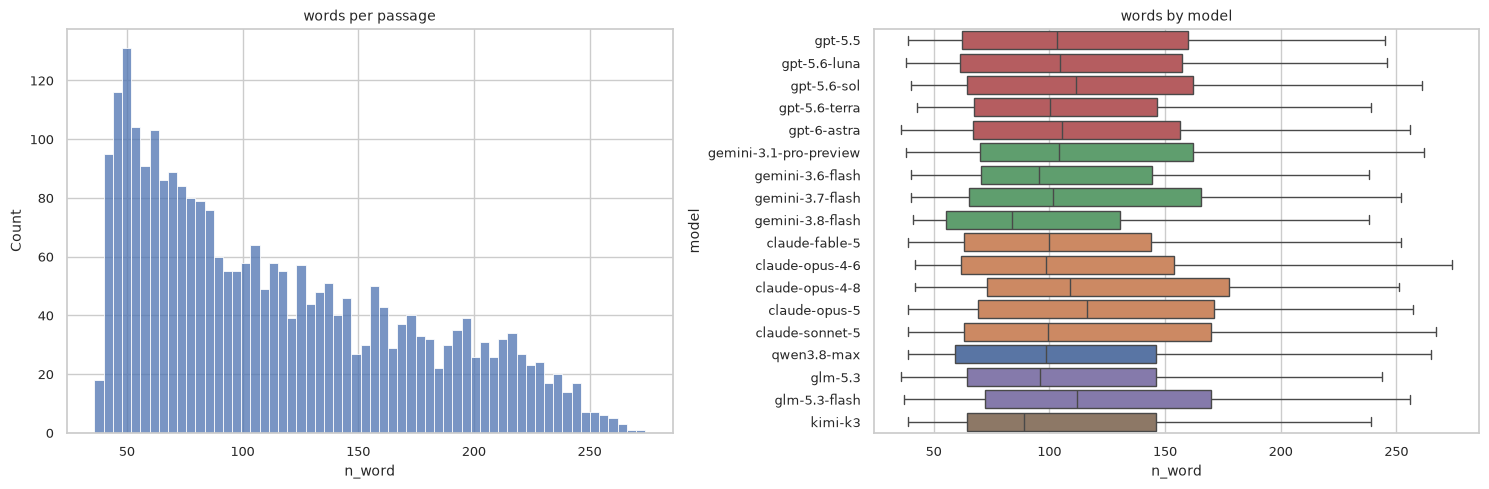

In [3]:
tr['n_char'] = tr.text.str.len()
tr['n_word'] = tr.text.str.split().str.len()
tr['n_para'] = tr.text.str.count(r'\n\s*\n') + 1
tr['n_line'] = tr.text.str.count('\n') + 1
print(tr[['n_char','n_word','n_para','n_line']].describe().T)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(tr.n_word, bins=60, ax=ax[0]); ax[0].set_title('words per passage')
sns.boxplot(data=tr, y='model', x='n_word', order=ORDER, hue='family', dodge=False, ax=ax[1], legend=False)
ax[1].set_title('words by model'); plt.tight_layout(); plt.show()

In [4]:
# 长度由 prompt 决定还是由模型决定？对 log 词数做两因素方差分解
lw = np.log(tr.n_word)
gm = lw.mean()
p_eff = tr.groupby('prompt_id').n_word.transform(lambda s: np.log(s).mean()) - gm
m_eff = tr.groupby('model').n_word.transform(lambda s: np.log(s).mean()) - gm
resid = lw - gm - p_eff - m_eff
tot = ((lw - gm) ** 2).sum()
print(f'prompt 解释 {(p_eff**2).sum()/tot:.1%} | model 解释 {(m_eff**2).sum()/tot:.1%} | 残差 {(resid**2).sum()/tot:.1%}')
# 模型在同一 prompt 内的长度相对排名（去掉 prompt 效应）
tr['len_rank'] = tr.groupby('prompt_id').n_word.rank(pct=True)
tr.groupby('model').agg(words_med=('n_word','median'), words_iqr=('n_word', lambda s: s.quantile(.75)-s.quantile(.25)),
                        in_prompt_rank=('len_rank','mean'), multi_para=('n_para', lambda s: (s>1).mean())).loc[ORDER]

prompt 解释 5.2% | model 解释 0.9% | 残差 94.0%


,words_med,words_iqr,in_prompt_rank,multi_para
model,,,,
gpt-5.5,103.5,97.75,0.509,0.0
gpt-5.6-luna,104.5,96.25,0.531,0.0
gpt-5.6-sol,111.5,98.00,0.540,0.0
gpt-5.6-terra,100.5,79.50,0.533,0.0
gpt-6-astra,105.5,89.50,0.544,0.0
gemini-3.1-pro-preview,104.0,91.75,0.557,0.0
gemini-3.6-flash,95.5,73.75,0.524,0.0
gemini-3.7-flash,101.5,100.50,0.543,0.0
gemini-3.8-flash,84.0,75.50,0.451,0.0


## 3. 标点与排版指纹
每个特征算两种量：**含有率**（多少比例的篇章出现过）和每千字符频率。

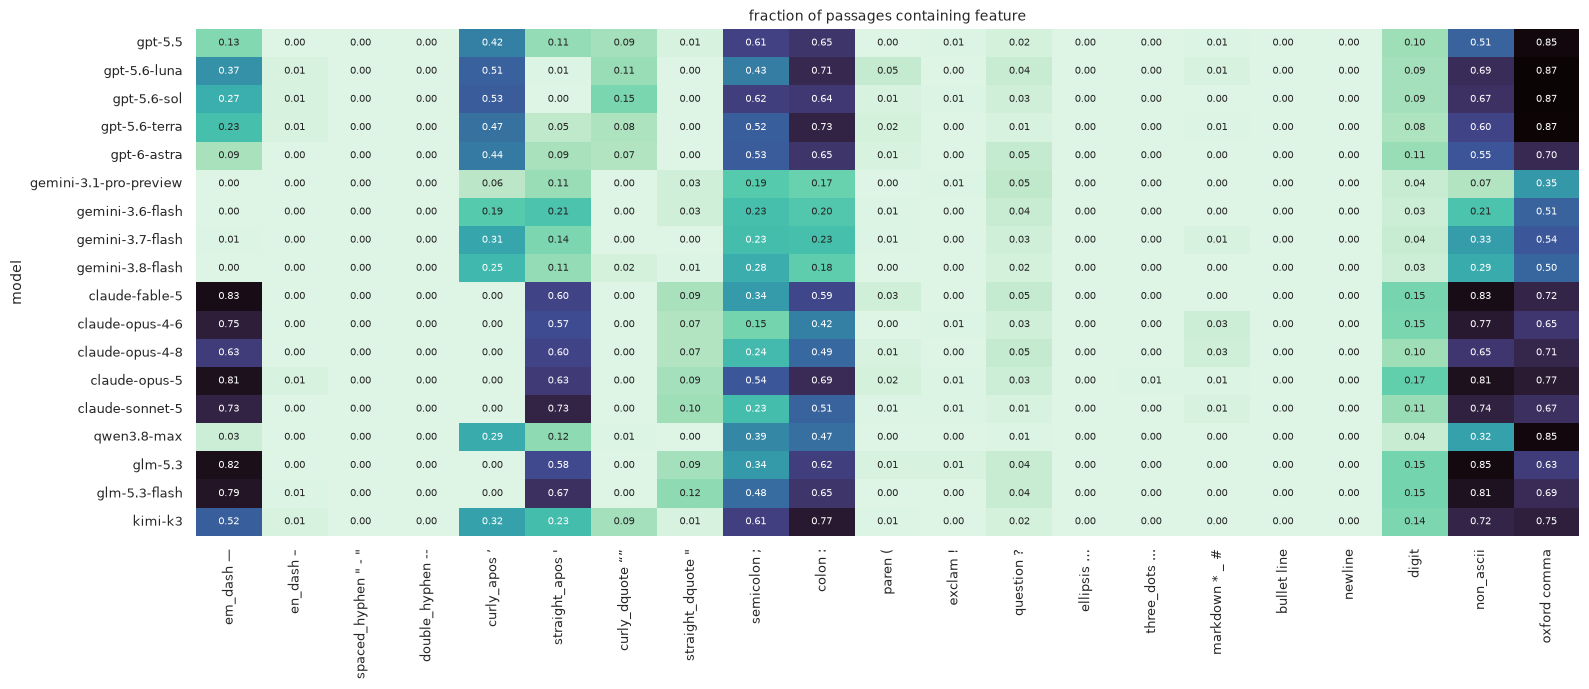

In [5]:
FEATS = {
    'em_dash —': '—', 'en_dash –': '–', 'spaced_hyphen " - "': ' - ', 'double_hyphen --': '--',
    'curly_apos ’': '’', 'straight_apos \'': "'", 'curly_dquote “”': '[“”]', 'straight_dquote "': '"',
    'semicolon ;': ';', 'colon :': ':', 'paren (': r'\(', 'exclam !': '!', 'question ?': r'\?',
    'ellipsis …': '…', 'three_dots ...': r'\.\.\.', 'markdown * _ #': r'[*_#`]', 'bullet line': r'(?m)^\s*([-*•]|\d+\.)\s',
    'newline': '\n', 'digit': r'\d', 'non_ascii': r'[^\x00-\x7f]', 'oxford comma': r', (and|or) ',
}
for name, pat in FEATS.items():
    cnt = tr.text.str.count(pat)
    tr['has:' + name] = (cnt > 0).astype(float)
    tr['rate:' + name] = cnt / tr.n_char * 1000
has = tr.groupby('model')[[c for c in tr if c.startswith('has:')]].mean().loc[ORDER]
has.columns = [c[4:] for c in has.columns]
plt.figure(figsize=(16, 7))
sns.heatmap(has, annot=True, fmt='.2f', cmap='mako_r', cbar=False, annot_kws={'size': 7})
plt.title('fraction of passages containing feature'); plt.tight_layout(); plt.show()

In [6]:
# 硬规则候选：某些模型从不出现某种字符（讨论区称 Claude / GLM 从不用弯撇号）
zero = (has == 0)
print('含有率恰为 0 的 (模型, 特征)：')
for f in has.columns:
    ms = list(has.index[zero[f]])
    if ms and len(ms) < 18: print(f'  {f:22s} -> {ms}')

含有率恰为 0 的 (模型, 特征)：
  em_dash —              -> ['gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.8-flash']
  en_dash –              -> ['gpt-5.5', 'gpt-6-astra', 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-sonnet-5', 'qwen3.8-max', 'glm-5.3']
  curly_apos ’           -> ['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'glm-5.3', 'glm-5.3-flash']
  straight_apos '        -> ['gpt-5.6-sol']
  curly_dquote “”        -> ['gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'glm-5.3', 'glm-5.3-flash']
  straight_dquote "      -> ['gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra', 'gemini-3.7-flash', 'qwen3.8-max']
  paren (                -> ['gpt-5.5', 'gemini-3.1-pro-preview', 'gemini-3.8-flash', 'claude-opus-4-6', 'qw

In [7]:
# 引号/撇号风格四象限：直/弯 撇号 × 直/弯 双引号
def quote_style(t):
    a = 'curly' if '’' in t else ('straight' if "'" in t else 'none')
    return a
tr['apos_style'] = tr.text.map(quote_style)
pd.crosstab(tr.model, tr.apos_style, normalize='index').loc[ORDER]

apos_style,curly,none,straight
model,,,
gpt-5.5,0.420,0.467,0.113
gpt-5.6-luna,0.513,0.480,0.007
gpt-5.6-sol,0.527,0.473,0.000
gpt-5.6-terra,0.467,0.480,0.053
gpt-6-astra,0.440,0.473,0.087
gemini-3.1-pro-preview,0.060,0.847,0.093
gemini-3.6-flash,0.193,0.620,0.187
gemini-3.7-flash,0.307,0.600,0.093
gemini-3.8-flash,0.247,0.647,0.107


In [8]:
# 非 ASCII 字符清单（除常见标点外）
nonascii = Counter(ch for t in tr.text for ch in t if ord(ch) > 127)
tab = pd.DataFrame([(c, f'U+{ord(c):04X}', unicodedata.name(c, '?'), n) for c, n in nonascii.most_common(30)],
                   columns=['char', 'code', 'name', 'count'])
tab

,char,code,name,count
0,—,U+2014,EM DASH,1835
1,’,U+2019,RIGHT SINGLE QUOTATION MARK,840
2,“,U+201C,LEFT DOUBLE QUOTATION MARK,125
3,”,U+201D,RIGHT DOUBLE QUOTATION MARK,125
4,ö,U+00F6,LATIN SMALL LETTER O WITH DIAERESIS,67
5,é,U+00E9,LATIN SMALL LETTER E WITH ACUTE,30
6,à,U+00E0,LATIN SMALL LETTER A WITH GRAVE,28
7,ç,U+00E7,LATIN SMALL LETTER C WITH CEDILLA,21
8,–,U+2013,EN DASH,18
9,−,U+2212,MINUS SIGN,12


## 4. 句子与词汇层面的文体量

In [9]:
sent_split = re.compile(r'(?<=[.!?])\s+')
def stylo(t):
    sents = [s for s in sent_split.split(t.strip()) if s]
    words = re.findall(r"[A-Za-z’']+", t)
    lw = [w.lower() for w in words]
    return pd.Series({
        'n_sent': len(sents),
        'words_per_sent': len(words) / max(len(sents), 1),
        'sent_len_std': np.std([len(s.split()) for s in sents]) if len(sents) > 1 else 0,
        'char_per_word': np.mean([len(w) for w in words]) if words else 0,
        'ttr': len(set(lw)) / max(len(lw), 1),
        'commas_per_sent': t.count(',') / max(len(sents), 1),
        'first_person': sum(w in {'i','me','my','we','our','us'} for w in lw) / max(len(lw), 1) * 100,
        'second_person': sum(w in {'you','your'} for w in lw) / max(len(lw), 1) * 100,
        'starts_with_the': float(t.lstrip().lower().startswith('the ')),
    })
st = tr.text.apply(stylo)
tr = pd.concat([tr, st], axis=1)
st.groupby(tr.model).mean().loc[ORDER]

,n_sent,words_per_sent,sent_len_std,char_per_word,ttr,commas_per_sent,first_person,second_person,starts_with_the
model,,,,,,,,,
gpt-5.5,4.333,26.488,5.664,5.154,0.826,2.928,0.915,0.331,0.067
gpt-5.6-luna,4.893,23.902,5.340,5.483,0.824,2.462,0.911,0.308,0.113
gpt-5.6-sol,4.940,25.094,6.136,5.395,0.826,2.568,0.905,0.237,0.087
gpt-5.6-terra,4.447,26.519,6.099,5.376,0.831,2.860,0.676,0.174,0.080
gpt-6-astra,5.547,21.206,5.223,5.242,0.819,1.672,0.998,0.682,0.087
gemini-3.1-pro-preview,5.767,20.276,5.212,5.495,0.804,1.535,1.532,0.604,0.147
gemini-3.6-flash,4.593,24.712,5.010,5.710,0.828,2.135,0.972,0.560,0.053
gemini-3.7-flash,4.807,23.934,4.997,5.928,0.841,1.919,0.858,0.534,0.067
gemini-3.8-flash,4.420,22.770,5.130,5.887,0.860,1.993,0.880,0.589,0.060


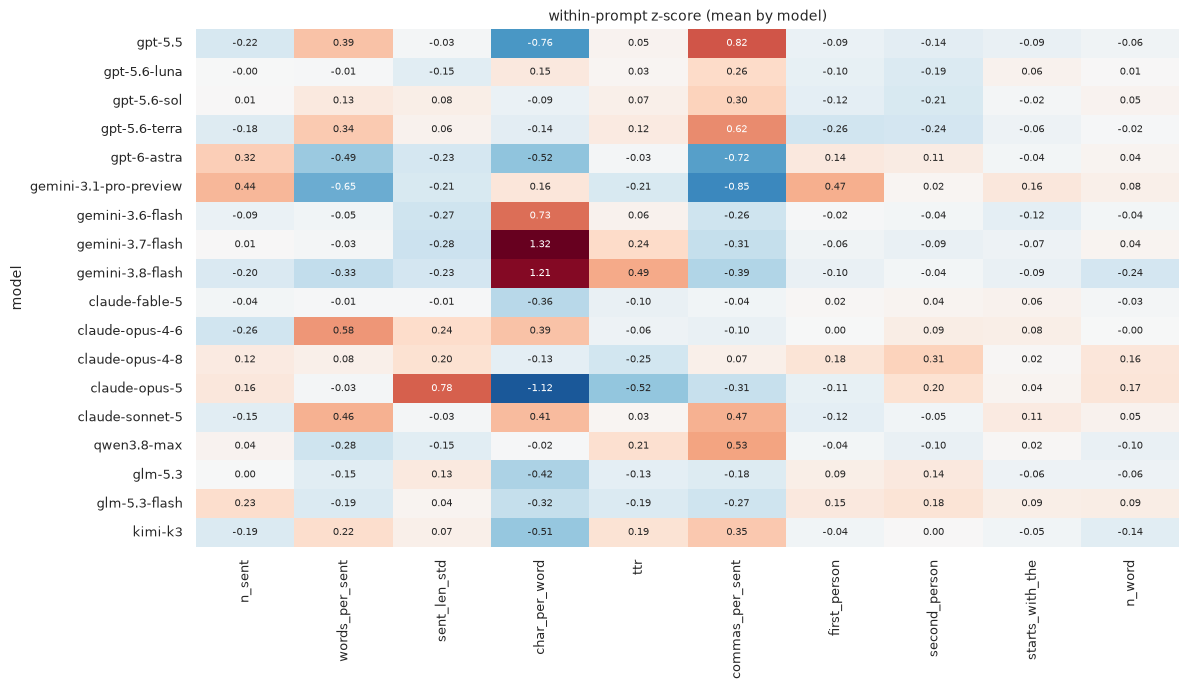

In [10]:
# 同一 prompt 内做 z-score，去掉话题对文体量的影响后再看模型差异
cols = list(st.columns) + ['n_word']
z = tr.groupby('prompt_id')[cols].transform(lambda s: (s - s.mean()) / (s.std() + 1e-9))
plt.figure(figsize=(12, 7))
sns.heatmap(z.groupby(tr.model).mean().loc[ORDER], annot=True, fmt='.2f', cmap='RdBu_r', center=0, cbar=False, annot_kws={'size': 7})
plt.title('within-prompt z-score (mean by model)'); plt.tight_layout(); plt.show()

## 5. 开头与高区分度词

In [11]:
first2 = tr.text.str.strip().str.split().str[:2].str.join(' ')
top_open = (tr.assign(first2=first2).groupby('model').first2
            .agg(lambda s: ' | '.join(f'{k} ({v})' for k, v in s.value_counts().head(4).items())).loc[ORDER])
print(top_open.to_string())
print('\n开头前两词的种类数 / 150:', first2.groupby(tr.model).nunique().loc[ORDER].to_dict())

model
gpt-5.5                   Across the (4) | At the (3) | In a (3) | When ...
gpt-5.6-luna              At the (5) | In the (5) | Imagine a (4) | In a...
gpt-5.6-sol               In the (5) | At the (4) | When a (3) | Deep wi...
gpt-5.6-terra             At the (6) | Across the (4) | When the (4) | W...
gpt-6-astra               Across the (4) | In the (4) | Imagine a (4) | ...
gemini-3.1-pro-preview    In the (7) | Imagine a (5) | Deep within (4) |...
gemini-3.6-flash          In the (8) | Beneath the (8) | Deep within (6)...
gemini-3.7-flash          Beneath the (9) | Deep within (7) | At the (6)...
gemini-3.8-flash          Beneath the (7) | Across the (6) | In the (6) ...
claude-fable-5            In the (8) | At the (5) | Beneath the (4) | Co...
claude-opus-4-6           In the (8) | At the (4) | Imagine a (2) | If e...
claude-opus-4-8           In the (10) | Imagine a (5) | At the (4) | Whe...
claude-opus-5             In the (4) | There is (4) | Beneath the (3) | ...
claude

In [12]:
# 加权 log-odds（Monroe et al. 2008，Dirichlet 先验）：每个模型 vs 其余模型
cv = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b[a-z][a-z’'-]+\b", min_df=5)
X = cv.fit_transform(tr.text)
vocab = np.array(cv.get_feature_names_out())
prior = np.asarray(X.sum(0)).ravel() + 0.01
a0 = prior.sum()
rows = {}
for m in ORDER:
    yi = np.asarray(X[(tr.model == m).values].sum(0)).ravel()
    yj = np.asarray(X[(tr.model != m).values].sum(0)).ravel()
    ni, nj = yi.sum(), yj.sum()
    d = np.log((yi + prior) / (ni + a0 - yi - prior)) - np.log((yj + prior) / (nj + a0 - yj - prior))
    var = 1 / (yi + prior) + 1 / (yj + prior)
    zz = d / np.sqrt(var)
    rows[m] = ', '.join(vocab[np.argsort(-zz)[:12]])
pd.Series(rows, name='most over-used words').to_frame()

,most over-used words
gpt-5.5,"speech, habits, legal, else’s, like, blue-whit..."
gpt-5.6-luna,"may, records, while, clues, therefore, can, bu..."
gpt-5.6-sol,"fled, combine, quarrel, and, limited, continua..."
gpt-5.6-terra,"crowded, may, entered, targets, institutions, ..."
gpt-6-astra,"familiar, helps, helped, can, shelter, ocean’s..."
gemini-3.1-pro-preview,"of, profound, our, absolute, ultimate, biologi..."
gemini-3.6-flash,"of, dynamic, expanse, breathtaking, void, math..."
gemini-3.7-flash,"an, of, profound, fundamentally, supreme, expa..."
gemini-3.8-flash,"an, tempest, permanently, enduring, transformi..."
claude-fable-5,"she, legitimate, shorter, insisting, slice, to..."


## 6. 话题泄漏：同 prompt 的文本有多像？
用 TF-IDF 最近邻看：一段文本最相似的其他文本是否来自同一 prompt（测试集 prompt 不在训练集，这是随机 CV 偏差的来源）。

In [13]:
tf = TfidfVectorizer(sublinear_tf=True, stop_words='english', min_df=2).fit_transform(tr.text)
S = (tf @ tf.T).toarray(); np.fill_diagonal(S, -1)
nn = S.argmax(1)
print('最近邻同 prompt 的比例:', (tr.prompt_id.values[nn] == tr.prompt_id.values).mean().round(3))
print('最近邻同模型的比例:', (tr.model.values[nn] == tr.model.values).mean().round(3))
pid = tr.prompt_id.to_numpy(dtype=object)
same = pid[:, None] == pid[None, :]
mask = ~np.eye(len(tr), dtype=bool)
print('cos 相似度  同prompt 均值 %.3f | 不同prompt 均值 %.3f' % (S[same & mask].mean(), S[~same].mean()))

最近邻同 prompt 的比例: 0.998
最近邻同模型的比例: 0.001
cos 相似度  同prompt 均值 0.226 | 不同prompt 均值 0.012


## 7. 分组 CV 基线
5 折 `StratifiedGroupKFold(groups=prompt_id)`。三组特征：(a) 字符+词 TF-IDF；(b) 只用第 2–4 节的手工文体特征；(c) 两者概率平均。

In [14]:
y = tr.model.to_numpy(dtype=object)
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(tr, y, groups=tr.prompt_id))
classes = np.array(sorted(ORDER))

def oof_tfidf():
    P = np.zeros((len(tr), 18))
    cfgs = [dict(analyzer='char', ngram_range=(1, 5), max_features=300_000),
            dict(analyzer='word', ngram_range=(1, 2), max_features=200_000, token_pattern=r'(?u)\b\w+\b|[^\w\s]')]
    for trn, val in folds:
        vs = [TfidfVectorizer(sublinear_tf=True, lowercase=False, min_df=2, **c) for c in cfgs]
        Xt = hstack([v.fit_transform(tr.text.iloc[trn]) for v in vs]).tocsr()
        Xv = hstack([v.transform(tr.text.iloc[val]) for v in vs]).tocsr()
        P[val] = LogisticRegression(C=10, max_iter=3000).fit(Xt, y[trn]).predict_proba(Xv)
    return P

hand_cols = [c for c in tr if c.startswith(('has:', 'rate:'))] + list(st.columns) + ['n_char', 'n_word', 'n_para']
def oof_hand():
    P = np.zeros((len(tr), 18)); Xh = tr[hand_cols].values
    for trn, val in folds:
        P[val] = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=5000)).fit(Xh[trn], y[trn]).predict_proba(Xh[val])
    return P

P_tf, P_hand = oof_tfidf(), oof_hand()
P_mix = np.exp(0.7 * np.log(P_tf + 1e-9) + 0.3 * np.log(P_hand + 1e-9))
res = {}
for name, P in [('tfidf', P_tf), ('hand-crafted', P_hand), ('blend', P_mix)]:
    pred = classes[P.argmax(1)]
    fam_acc = (pd.Series(pred).map(FAMILY).values == tr.family.values).mean()
    res[name] = dict(bal_acc=balanced_accuracy_score(y, pred), family_acc=fam_acc,
                     fold_std=np.std([balanced_accuracy_score(y[v], pred[v]) for _, v in folds]))
pd.DataFrame(res).T

,bal_acc,family_acc,fold_std
tfidf,0.343,0.702,0.014
hand-crafted,0.273,0.609,0.026
blend,0.380,0.724,0.022


In [15]:
pred = classes[P_mix.argmax(1)]
rec = pd.DataFrame({m: {'tfidf': recall_score(y, classes[P_tf.argmax(1)], labels=[m], average='macro'),
                        'hand': recall_score(y, classes[P_hand.argmax(1)], labels=[m], average='macro'),
                        'blend': recall_score(y, pred, labels=[m], average='macro')} for m in ORDER}).T
rec['family'] = rec.index.map(FAMILY)
rec

,tfidf,hand,blend,family
gpt-5.5,0.273,0.327,0.427,OpenAI
gpt-5.6-luna,0.307,0.247,0.327,OpenAI
gpt-5.6-sol,0.213,0.107,0.213,OpenAI
gpt-5.6-terra,0.227,0.153,0.200,OpenAI
gpt-6-astra,0.480,0.420,0.600,OpenAI
gemini-3.1-pro-preview,0.660,0.660,0.780,Google
gemini-3.6-flash,0.433,0.207,0.413,Google
gemini-3.7-flash,0.400,0.307,0.420,Google
gemini-3.8-flash,0.327,0.280,0.360,Google
claude-fable-5,0.107,0.087,0.101,Anthropic


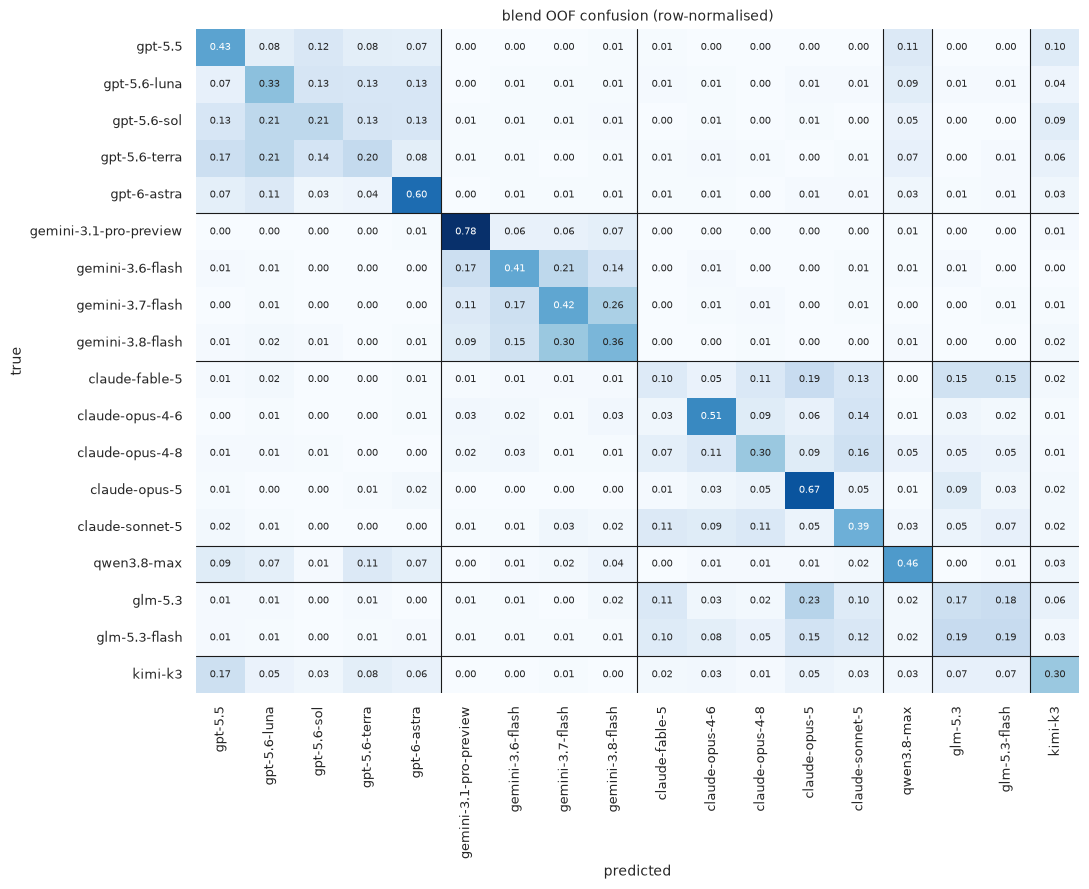

In [16]:
cm = confusion_matrix(y, pred, labels=ORDER, normalize='true')
plt.figure(figsize=(11, 9))
sns.heatmap(cm, xticklabels=ORDER, yticklabels=ORDER, annot=True, fmt='.2f', cmap='Blues', cbar=False, annot_kws={'size': 7})
for b in np.cumsum([5, 4, 5, 1, 2]):  # 家族分隔线
    plt.axhline(b, color='k', lw=0.8); plt.axvline(b, color='k', lw=0.8)
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('blend OOF confusion (row-normalised)')
plt.tight_layout(); plt.show()

In [17]:
# 最常见的混淆对 & 家族层面混淆
off = pd.DataFrame(cm, index=ORDER, columns=ORDER).stack()
off = off[[a != b for a, b in off.index]].sort_values(ascending=False)
print(off.head(12).round(3).to_string())
fam_order = ['OpenAI', 'Google', 'Anthropic', 'Qwen', 'ZAI', 'Moonshot']
print()
print(pd.crosstab(tr.family, pd.Series(pred).map(FAMILY).values, normalize='index').loc[fam_order, fam_order].round(2))

gemini-3.8-flash  gemini-3.7-flash          0.300
gemini-3.7-flash  gemini-3.8-flash          0.260
glm-5.3           claude-opus-5             0.233
gemini-3.6-flash  gemini-3.7-flash          0.213
gpt-5.6-terra     gpt-5.6-luna              0.213
gpt-5.6-sol       gpt-5.6-luna              0.213
glm-5.3-flash     glm-5.3                   0.193
claude-fable-5    claude-opus-5             0.188
glm-5.3           glm-5.3-flash             0.180
gemini-3.6-flash  gemini-3.1-pro-preview    0.173
gpt-5.6-terra     gpt-5.5                   0.173
kimi-k3           gpt-5.5                   0.167

col_0      OpenAI  Google  Anthropic  Qwen   ZAI  Moonshot
family                                                    
OpenAI       0.81    0.02       0.03  0.07  0.01      0.06
Google       0.02    0.94       0.01  0.01  0.00      0.01
Anthropic    0.03    0.05       0.74  0.02  0.14      0.02
Qwen         0.36    0.07       0.06  0.46  0.01      0.03
ZAI          0.04    0.03       0.50  0.02  0

In [18]:
# 准确率随长度变化（短文本更难？）
bins = pd.qcut(tr.n_word, 5)
tr.assign(ok=(pred == y)).groupby(bins, observed=True).ok.mean().rename('accuracy').to_frame().T

n_word,"(35.999, 59.0]","(59.0, 84.0]","(84.0, 121.0]","(121.0, 171.0]","(171.0, 274.0]"
accuracy,0.281,0.341,0.379,0.43,0.471


## 8. 结论

**数据结构**
- 150 个 prompt × 18 个模型，只缺 1 条（claude-fable-5）。没有重复文本，所有文本都是单段落、无换行，markdown 符号也几乎没有。
- 长度：36–274 词，中位数 101。方差中 prompt 只解释 5%，模型只解释 0.9%，**长度基本没有区分力**；只有 gemini-3.8-flash 和 kimi-k3 偏短一点。
- 话题泄漏很强：TF-IDF 最近邻有 99.8% 来自同一 prompt，同模型只有 0.1%。**必须按 prompt 分组做 CV。**

**排版指纹**（训练集上的含有率；能否当硬规则，要先用外部数据验证）
- **弯引号**：Claude 全系和 GLM 两个模型都是 0（讨论区说的 Claude / GLM 不用 `’` 得到印证）；OpenAI 系出现在 42–53% 的篇章中。
- **em dash**：Claude 和 GLM 出现在 63–83% 的篇章中；Gemini 几乎为 0；Qwen 3%；GPT-5.5 和 gpt-6-astra 只有 9–13%；kimi 52%。
- **分号和冒号**：OpenAI 系和 kimi 偏高（分号 43–62%），Gemini 和 Claude-4.x 偏低。
- 只看标点就能**区分到家族**：OpenAI 是“弯撇号 + 少量 em dash”，Gemini 是“没有 em dash”，Claude/GLM 是“em dash + 直引号”。但**家族内部**的模型很难靠标点分开。

**分组 CV 基线**（5 折，balanced accuracy）
| 特征 | bal_acc | 家族准确率 |
|---|---|---|
| char+word TF-IDF + LR | 0.343 | 0.70 |
| 手工文体特征 + LR | 0.273 | 0.61 |
| 两者混合 | **0.380** | 0.72 |

- 容易分的：gemini-3.1-pro（0.78）、claude-opus-5（0.67）、gpt-6-astra（0.60）。
- 难分的：claude-fable-5（0.10）、glm-5.3 / glm-5.3-flash（0.17–0.19）、gpt-5.6-sol / terra（约 0.2）。
- 主要错误：
  - **家族内部**：gemini 3.6 / 3.7 / 3.8 互相混；gpt-5.6 三兄弟互相混。
  - **跨家族**：ZAI 有 50% 被判成 Anthropic（GLM 写得像 Claude）；Qwen 和 Kimi 分别有 36% 和 39% 被判成 OpenAI。
- 文本越短越难：最短的五分之一准确率 0.28，最长的五分之一 0.47。

**下一步方向**
- 家族已经能分对 72%，真正的瓶颈在家族内部区分，以及 GLM↔Claude、Qwen/Kimi↔OpenAI 这两类跨家族混淆。
- 只有 2.7k 条训练数据，上限很低，外部数据（Open Pool）加上 LLM 微调是主线。
- 排版规则只能当作软先验（乘一个小系数），用之前要先在外部数据上检查它的稳定性。
